In [61]:
import numpy as np
import galois
import json
import sys
import os

GF = galois.GF2
from stimbposd import SinterDecoder_BPOSD

In [62]:
meta_n, meta_k, d_str = 48, 4, 8 
print(os.getcwd())
H_x = np.loadtxt("Codes/48_4_Coset2BGA/coset2bga_n48_k4_d8_Hx.txt", dtype=int)
H_z = np.loadtxt("Codes/48_4_Coset2BGA/coset2bga_n48_k4_d8_Hz.txt", dtype=int)

rank_X = np.linalg.matrix_rank(GF(H_x))
rank_Z = np.linalg.matrix_rank(GF(H_z))
    
    # 2. k = n - rank(H_X) - rank(H_Z)
calculated_k = H_x.shape[1] - rank_X - rank_Z
    
    # 3. Check for a match
k_match = "MATCH" if calculated_k == meta_k else f"MISMATCH (Calculated: {calculated_k})"

print(f"--- Code Sanity Check ---")
print(f"Code parameters: [[{meta_n}, {meta_k}, {d_str}]]")
print(f"data qubits = {H_x.shape[1]}")
print(f"X checks = {H_x.shape[0]} (Rank: {rank_X})")
print(f"Z checks = {H_z.shape[0]} (Rank: {rank_Z})")
print(f"logical qubits (meta) = {meta_k} [{k_match}]")
print(f"-------------------------")

/home/ukech/Simula_UiB/Research/Code/LocASC
--- Code Sanity Check ---
Code parameters: [[48, 4, 8]]
data qubits = 48
X checks = 24 (Rank: 22)
Z checks = 24 (Rank: 22)
logical qubits (meta) = 4 [MATCH]
-------------------------


In [63]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

def load_and_process_json(filepath):
    """Parses the JSON lines output, aggregates by p, and computes LER uncertainties."""
    rows = []
    with open(filepath, 'r') as f:
        for line in f:
            if not line.strip():
                continue
            rows.append(json.loads(line))
            
    df = pd.DataFrame(rows)
    if df.empty:
        return df, None, None

    # ==========================================
    # AGGREGATE SHOTS AND ERRORS BY p
    # ==========================================
    df = df.groupby('p', as_index=False).agg({
        'shots_x': 'sum',
        'errors_x': 'sum',
        'shots_z': 'sum',
        'errors_z': 'sum',
        'd': 'first',
        'k': 'first'
    })

    # Standardize column names for the fitting function
    d = df['d'].iloc[0]
    k = df['k'].iloc[0]

    # Calculate raw block error rates
    raw_x = df['errors_x'] / df['shots_x']
    raw_z = df['errors_z'] / df['shots_z']
    
    # Safe variables to prevent division by zero or negative fractional roots
    safe_raw_x = np.minimum(raw_x, 1.0 - 1e-10)
    safe_raw_z = np.minimum(raw_z, 1.0 - 1e-10)
    
    # Per-round logical error rates (will be 0 if errors are 0)
    df['pL_x'] = 1 - (1 - safe_raw_x)**(1/d)
    df['pL_z'] = 1 - (1 - safe_raw_z)**(1/d)
    
    # Base standard errors for the raw block rates (binomial distribution)
    # Re-added the np.maximum(..., 1) to provide valid error bars for 0-error points
    safe_errors_x = np.maximum(df['errors_x'], 1)
    safe_p_fail_x = safe_errors_x / df['shots_x']
    err_x = np.sqrt(safe_p_fail_x * (1 - safe_p_fail_x) / df['shots_x'])

    safe_errors_z = np.maximum(df['errors_z'], 1)
    safe_p_fail_z = safe_errors_z / df['shots_z']
    err_z = np.sqrt(safe_p_fail_z * (1 - safe_p_fail_z) / df['shots_z'])
    
    # Propagate error through the 1 - (1-x)^(1/d) transformation
    df['pL_err_x'] = (1/d) * (1 - safe_raw_x)**(1/d - 1) * err_x
    df['pL_err_z'] = (1/d) * (1 - safe_raw_z)**(1/d - 1) * err_z

    # The total aggregated LER
    df['total_pL'] = 1 - (1 - df['pL_x']) * (1 - df['pL_z'])
    
    # Propagate error to the total aggregated LER
    df['total_pL_err'] = np.sqrt(
        ((1 - df['pL_z']) * df['pL_err_x'])**2 + 
        ((1 - df['pL_x']) * df['pL_err_z'])**2
    )

    return df.sort_values('p'), k, d

def get_fit_params(df, k, d_circ):
    # This automatically filters out pL = 0 points for the fit
    df_valid = df[df['total_pL'] > 0].copy()
    
    log_p = np.log(df_valid['p'].values)
    pL = df_valid['total_pL'].values
    pL_err = df_valid['total_pL_err'].values
    
    log_pL_err = np.maximum(pL_err, 1e-15) / pL
    weights = 1.0 / log_pL_err
    
    poly_coeffs = np.polyfit(log_p, np.log(pL), 2)
    poly = np.poly1d(poly_coeffs)
    
    p_ps = fsolve(lambda p: np.exp(poly(np.log(p))) - (1 - (1 - p)**k), 0.0055)[0]
    
    df_sub = df_valid[df_valid['p'] < p_ps]
    p_s = df_sub['p'].values
    pL_s = df_sub['total_pL'].values
    pL_err_s = df_sub['total_pL_err'].values
    
    exponent = d_circ / 2.0
    y = np.log(pL_s) - exponent * np.log(p_s)
    
    y_err = np.maximum(pL_err_s, 1e-15) / pL_s
    weights_sub = 1.0 / y_err
    
    c2, c1, c0 = np.polyfit(p_s, y, 2, w=weights_sub)
    
    return p_ps, (c0, c1, c2), exponent

def extrap(p, c, e): 
    return (p**e) * np.exp(c[0] + c[1]*p + c[2]*p**2)

def plot_qec_results(file_configs):
    plt.rcParams.update({'font.size': 12})
    plt.figure(figsize=(10, 8)) 

    x_min, x_max = 9e-5, 0.01
    p_fine = np.logspace(np.log10(x_min), np.log10(x_max), 1000)
    
    # -------------------------------------------------------------
    # THRESHOLD FOR MAX ERROR BAR SIZE (0.5 = 50% relative error)
    # -------------------------------------------------------------
    max_rel_err = 1

    for filepath, color, marker, lbl, d_circ in file_configs:
        df, k, d = load_and_process_json(filepath)
        if df.empty:
            continue
            
        p_ps, coeffs, exp = get_fit_params(df, k, d_circ)
        
        # ==========================================================
        # 1. Drop max points above pseudo-threshold
        # ==========================================================
        df_plot = df[(df['p'] >= x_min) & (df['p'] <= x_max) & (df['p'] <= x_max)].copy()
        
        # ==========================================================
        # 2. FILTER OUT POINTS WITH MASSIVE ERROR BARS
        # ==========================================================
        # Calculate the relative error (uncertainty / value)
        # We use a safe division to avoid warnings if total_pL happens to be 0
        safe_pL = np.maximum(df_plot['total_pL'], 1e-15)
        relative_error = df_plot['total_pL_err'] / safe_pL
        
        # Only keep points where the relative error is acceptable
        df_plot = df_plot[relative_error <= max_rel_err]
        
        # Plot data points with error bars
        plt.errorbar(df_plot['p'], df_plot['total_pL'], yerr=df_plot['total_pL_err'], 
                     fmt=marker, color=color, capsize=3, alpha=0.8, label=lbl, markersize=6)
        
        # ==========================================================
        # 3. Stop extrapolation line at the first point under the threshold
        # ==========================================================
        sub_threshold_points = df[df['p'] < p_ps]['p']
        stop_line_p = sub_threshold_points.max() if not sub_threshold_points.empty else p_ps
            
        p_fine_sub = p_fine[p_fine <= stop_line_p]
        plt.plot(p_fine_sub, extrap(p_fine_sub, coeffs, exp), '-.', color=color, linewidth=2)
        
        # Optional: break-even line
        plt.plot(p_fine, 1 - (1 - p_fine)**k, '--', color=color, alpha=0.25)

    plt.xscale('log')
    plt.yscale('log')
    plt.xlim(x_min, x_max)
    plt.ylim(1e-13, 1e-1)

    plt.title('Circuit Level Performance', fontsize=18, pad=15)
    plt.xlabel('Physical Error Rate ($p$)', fontsize=18)
    plt.ylabel('Logical Error Rate per Syndrome Cycle ($p_L$)', fontsize=18)

    plt.legend(loc='lower right', fontsize=16, framealpha=0.9, edgecolor='gray')
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout() 

    plt.show()


def export_pgfplots_data(file_configs, output_dir="plot_data"):
    os.makedirs(output_dir, exist_ok=True)
    x_min, x_max = 9e-5, 0.01
    p_fine = np.logspace(np.log10(x_min), np.log10(x_max), 1000)
    max_rel_err = 1  # Filter out error bars larger than 50% of the value

    for filepath, lbl, d_circ in file_configs:
        df, k, d = load_and_process_json(filepath)
        if df.empty: continue
            
        p_ps, coeffs, exp = get_fit_params(df, k, d_circ)
        
        # 1. Filter and Export Data Points
        df_plot = df[(df['p'] >= x_min) & (df['p'] <= x_max) & (df['p'] <= p_ps)].copy()
        
        # Drop massive error bars
        relative_error = df_plot['total_pL_err'] / np.maximum(df_plot['total_pL'], 1e-15)
        df_plot = df_plot[relative_error <= max_rel_err]
        
        df_plot[['p', 'total_pL', 'total_pL_err']].to_csv(os.path.join(output_dir, f"{lbl}_data.csv"), index=False)
        
        # 2. Export Fitted Sub-threshold Curve (stop at first point under pseudo-threshold)
        sub_threshold_points = df[df['p'] < p_ps]['p']
        stop_line_p = sub_threshold_points.max() if not sub_threshold_points.empty else p_ps
        
        p_fine_sub = p_fine[p_fine <= stop_line_p]
        pd.DataFrame({'p': p_fine_sub, 'pL': extrap(p_fine_sub, coeffs, exp)}).to_csv(os.path.join(output_dir, f"{lbl}_fit.csv"), index=False)
        
        # 3. Export Break-even Line
        pd.DataFrame({'p': p_fine, 'pL': 1 - (1 - p_fine)**k}).to_csv(os.path.join(output_dir, f"{lbl}_breakeven.csv"), index=False)
        
        print(f"Exported {lbl} data to ./{output_dir}/")

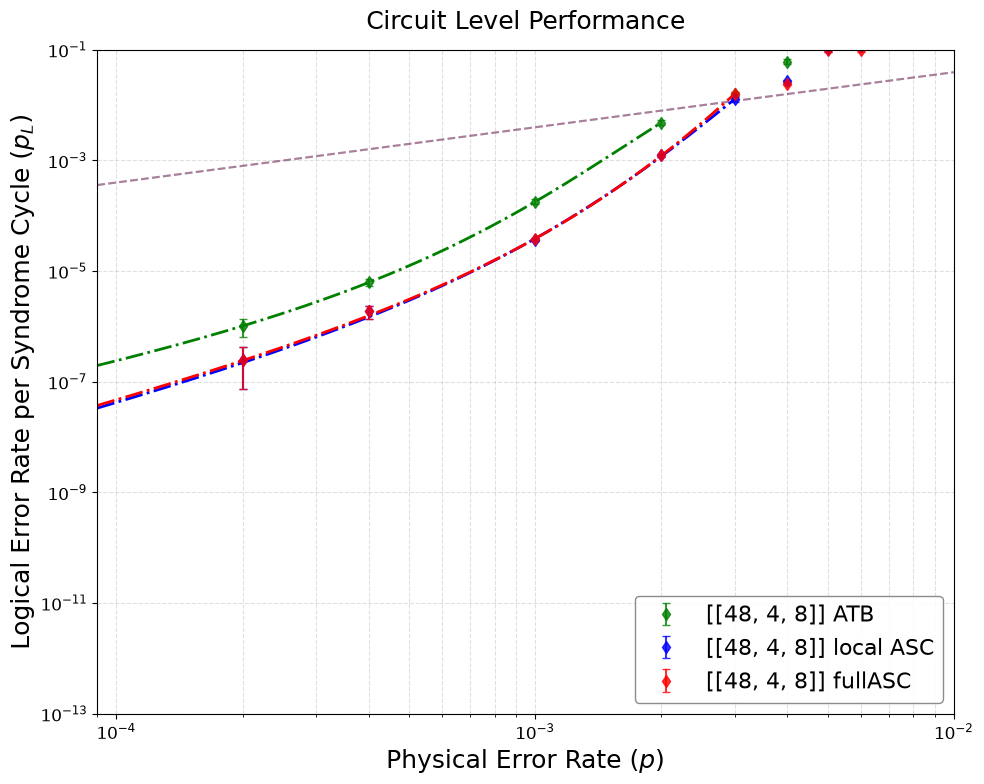

Exported 48_4_d8_ATB data to ./plot_data/
Exported 48_4_d8_localASC data to ./plot_data/
Exported 48_4_d8_fullASC data to ./plot_data/


In [64]:
configs = [
        ("results/ATB_official_n48_k4_d8_depth7_nshots1000001.json", "green", "d", "[[48, 4, 8]] ATB", 3),("results/localASC_n48_k4_d8_depth6_nshots1000000.json", "blue", "d", "[[48, 4, 8]] local ASC", 4),
                ("results/fullASC_n48_k4_d8_depth6_nshots1000000.json", "red", "d", "[[48, 4, 8]] fullASC", 4)
    ]

configs_latex = [
        ("results/ATB_official_n48_k4_d8_depth7_nshots1000001.json", "48_4_d8_ATB", 4),("results/localASC_n48_k4_d8_depth6_nshots1000000.json", "48_4_d8_localASC", 4),
        ("results/fullASC_n48_k4_d8_depth6_nshots1000000.json", "48_4_d8_fullASC", 4)        
    ]

plot_qec_results(configs)
export_pgfplots_data(configs_latex)

In [65]:
stim_circuit_filepath = "Codes/48_4_"